# 决策树

- 决策树是一种用"一连串是非问题"来做预测的监督学习模型。
- 从根节点开始,每个内部节点问一个关于特征的问题(比如"年龄 > 30?"),根据答案走向不同分支,最后到达叶节点
- 叶节点给出预测结果。
- 它既能做分类(预测类别),也能做回归(预测数值)

- 根节点——树的起点,包含全部训练样本
- 内部节点——存放一个分裂条件(特征 j,阈值 s),把样本分到子节点
- 叶节点——不再分裂的终点,存放最终预测
- 深度——根到最远叶子的边数,代表一条预测路径最多问几个问题
- 叶子数——等于划分出的区域数,是模型复杂度最直接的度量

## 损失函数
- 训练决策树，就是找出一组问题，让树在训练集上的损失尽量小
- 损失——信息混乱程度（信息熵）的变化量
> - **_基尼不纯度 Gini impurity_**
> > 1. $G = 1 - \sum{p_i^2}$——有放回取出两次的类别不同的概率——基尼不纯度越低说明数据越整齐，信息熵越低
> > 2. **_加权不纯度_**——$G_{split} = \frac{n_l}{n}G_{left} + \frac{n_r}{n}G_{right}$
> > 3. 选择一个决策分界点后，数据被分成两份，现在的总基尼不纯度就是加权不纯度——目的就是尽可能降低基尼不纯度

- 一个例子
- 输入：[[1,5],[2,3],[3,4],[4,1]]
- 输出：[0,0,1,1]
-

In [9]:
import math
import torch

torch.set_num_threads(1)

# 两个月牙各 500 个点：上面的月牙是蓝点，标签为 0；下面的月牙是红点，标签为 1
generator = torch.Generator().manual_seed(2)
angle = math.pi * torch.rand(1000, generator=generator)
upper = torch.stack([torch.cos(angle[:500]), torch.sin(angle[:500])], dim=1)
lower = torch.stack([1 - torch.cos(angle[500:]), 0.5 - torch.sin(angle[500:])], dim=1)
# 每个坐标再加上标准差为 0.3 的随机噪声，两个月牙会有一部分交叠
x = torch.cat([upper, lower]) + 0.3 * torch.randn(1000, 2, generator=generator)
y = torch.cat([torch.zeros(500), torch.ones(500)])

# 打乱后按 6:2:2 分成训练集、验证集和测试集
order = torch.randperm(1000, generator=torch.Generator().manual_seed(42))
train_ids, val_ids, test_ids = order[:600], order[600:800], order[800:]
x_train, y_train = x[train_ids], y[train_ids]
x_val, y_val = x[val_ids], y[val_ids]
x_test, y_test = x[test_ids], y[test_ids]

In [15]:
# p 是节点里红点所占的比例，返回这个节点的基尼不纯度
def gini(p):
    return 1 - p ** 2 - (1 - p) ** 2


p = y_train.mean()
print(f"训练集：蓝点 {int((y_train == 0).sum())} 个，红点 {int(y_train.sum())} 个，基尼不纯度 {gini(p):.3f}")

训练集：蓝点 301 个，红点 299 个，基尼不纯度 0.500,0.498333


In [7]:
# 用某个特征的每个候选阈值切一刀，算出切分后的加权基尼不纯度
def split_scores(x, y, feature):
    # 这个特征的取值去重后从小到大排好，相邻两个值的中点就是候选阈值
    values = torch.unique(x[:, feature])
    thresholds = (values[:-1] + values[1:]) / 2
    # go_left 的第 i 行表示用第 i 个阈值切分时，每个点是否分到左边，形状是 (阈值个数, 点数)
    go_left = x[:, feature] <= thresholds[:, None]
    n_left = go_left.sum(dim=1)
    n_right = len(y) - n_left
    p_left = (go_left * y).sum(dim=1) / n_left
    p_right = (~go_left * y).sum(dim=1) / n_right
    # 两边的基尼不纯度按点数加权
    impurity = (n_left * gini(p_left) + n_right * gini(p_right)) / len(y)
    return thresholds, impurity

x₁ 有 599 个候选阈值，最好的是 x₁ ≤ -0.23，加权基尼不纯度 0.407
x₂ 有 599 个候选阈值，最好的是 x₂ ≤ 0.44，加权基尼不纯度 0.303


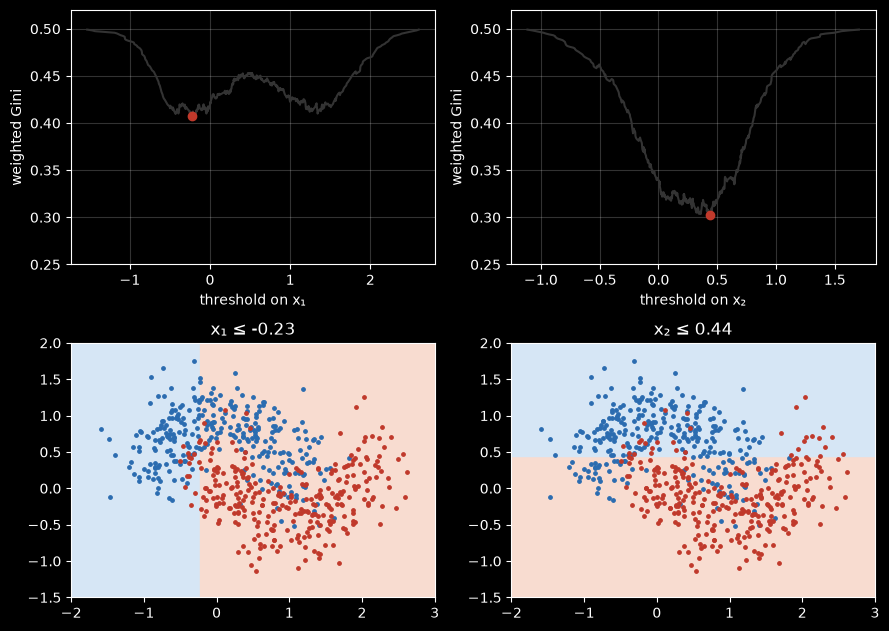

In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(9, 6.4))
for feature in range(2):
    thresholds, impurity = split_scores(x_train, y_train, feature)
    i = impurity.argmin()
    threshold = thresholds[i].item()
    name = ["x₁", "x₂"][feature]
    print(f"{name} 有 {len(thresholds)} 个候选阈值，最好的是 {name} ≤ {threshold:.2f}，加权基尼不纯度 {impurity[i]:.3f}")
    ax = axes[0, feature]
    ax.plot(thresholds, impurity, color="#333333")
    ax.scatter(thresholds[i], impurity[i], color="#c0392b", zorder=3)
    ax.set(xlabel=f"threshold on {name}", ylabel="weighted Gini", ylim=(0.25, 0.52))
    ax.grid(alpha=0.2)

    # 把最好的一刀画在训练点上，两边按多数点的颜色涂底色
    ax = axes[1, feature]
    span = ax.axvspan if feature == 0 else ax.axhspan
    left = x_train[:, feature] <= threshold
    for side, low, high in [(left, -2, threshold), (~left, threshold, 3)]:
        span(low, high, color="#f8dcd0" if y_train[side].mean() > 0.5 else "#d6e6f5")
    ax.scatter(x_train[y_train == 0, 0], x_train[y_train == 0, 1], s=6, color="#2b6cb0")
    ax.scatter(x_train[y_train == 1, 0], x_train[y_train == 1, 1], s=6, color="#c0392b")
    ax.set(xlim=(-2, 3), ylim=(-1.5, 2), aspect="equal", title=f"{name} ≤ {threshold:.2f}")
fig.tight_layout()
plt.show()